# Módulo 15: Soluciones basadas en datos — Solución

> Solución de referencia de la guía [m15-soluciones-basadas-en-datos-guia.ipynb](m15-soluciones-basadas-en-datos-guia.ipynb). No es una tarea entregada del programa.

Lección del módulo: [m15-soluciones-basadas-en-datos-leccion.md](m15-soluciones-basadas-en-datos-leccion.md)

## Contexto

**PulsoFit** es una cadena de 14 gimnasios en ciudades medianas. Vende membresías mensuales sin permanencia en tres planes: **Básico** (29 $ al mes, sala de máquinas), **Plus** (45 $, añade clases grupales) y **Premium** (69 $, añade todas las sedes, piscina y una sesión mensual con entrenador). Además cobra extras: clases especiales, entrenamiento personal y productos de su tienda.

El negocio crece en altas, pero la dirección está preocupada: muchos clientes cancelan a los pocos meses y cada nuevo cliente cuesta caro en publicidad y promociones de inscripción. La directora general quiere entender qué papel puede jugar la ciencia de datos en el modelo de negocio y, en concreto, **qué clientes se van, cuánto vale cada tipo de cliente y dónde conviene invertir para retenerlos**.

Para el cálculo del valor de vida del cliente, el área financiera estima que el **margen de contribución es del 40 %** de lo que paga cada cliente: el resto cubre instalaciones, personal y energía.

## Datos

La celda inicial genera el DataFrame `clientes`, una muestra de 2 400 clientes activos en la fecha de corte. Tiene una fila por cliente y estas columnas:

| Columna | Descripción |
| --- | --- |
| `cliente_id` | Identificador del cliente |
| `plan` | Plan contratado: `Básico`, `Plus` o `Premium` |
| `antiguedad_meses` | Meses como cliente en la fecha de corte |
| `visitas_mes` | Visitas promedio al mes en los tres meses previos al corte |
| `gasto_mensual` | Gasto promedio mensual en $ (cuota del plan más extras) |
| `abandono` | 1 si el cliente canceló su membresía en los **3 meses siguientes** al corte; 0 si siguió activo |

Los datos son sintéticos y se generan con una semilla fija, así que siempre obtendrás los mismos valores.

## Instrucciones

1. **Lienzo de modelo de negocio de PulsoFit:** completar los nueve bloques.
2. **Dónde crea valor la ciencia de datos:** al menos cuatro bloques, con decisión, datos y técnica.
3. **Oportunidades y amenazas:** tres de cada una y un balance final.
4. **Segmentar a los clientes:** estandarizar antigüedad, visitas y gasto, aplicar KMeans con 4 clústeres y nombrar los segmentos.
5. **Tasa de abandono por segmento:** por segmento y por plan, con gráfico de barras.
6. **Valor de vida del cliente (CLV):** convertir el abandono a 3 meses en tasa mensual, calcular la vida esperada y el CLV por segmento con margen del 40 %.
7. **Del análisis al lienzo:** peso de cada segmento en clientes, ingresos e ingreso en riesgo, y cambios en tres bloques del lienzo.

### Carga de los datos

La celda siguiente es idéntica a la de la guía: genera los mismos 2 400 clientes con la semilla 42.

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "1"  # evita un aviso de KMeans en Windows

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 2400

# Perfil latente de cada cliente (no forma parte de los datos que analizas)
perfil = rng.choice(4, size=n, p=[0.30, 0.35, 0.20, 0.15])
antiguedad = np.select(
    [perfil == 0, perfil == 1, perfil == 2, perfil == 3],
    [rng.integers(1, 7, n), rng.integers(6, 37, n), rng.integers(18, 85, n), rng.integers(4, 31, n)],
)
visitas = np.select(
    [perfil == 0, perfil == 1, perfil == 2, perfil == 3],
    [rng.gamma(4, 0.8, n), rng.normal(8, 1.8, n), rng.normal(14, 2.5, n), rng.gamma(4, 0.8, n)],
)
visitas = np.clip(visitas, 0.3, 24).round(1)

prob_plan = {0: [0.75, 0.20, 0.05], 1: [0.50, 0.40, 0.10], 2: [0.15, 0.40, 0.45], 3: [0.05, 0.25, 0.70]}
plan = np.array([rng.choice(["Básico", "Plus", "Premium"], p=prob_plan[k]) for k in perfil])
cuota = pd.Series(plan).map({"Básico": 29, "Plus": 45, "Premium": 69}).to_numpy()
extras = rng.gamma(2, np.select([perfil == 0, perfil == 1, perfil == 2, perfil == 3], [3, 6, 14, 18]))
gasto = (cuota + extras).round(2)

# Probabilidad de abandono en los 3 meses siguientes
logit = 0.5 - 0.15 * visitas - 0.25 * np.log(antiguedad)
abandono = rng.binomial(1, 1 / (1 + np.exp(-logit)))

clientes = pd.DataFrame({
    "cliente_id": np.arange(1, n + 1),
    "plan": plan,
    "antiguedad_meses": antiguedad,
    "visitas_mes": visitas,
    "gasto_mensual": gasto,
    "abandono": abandono,
})
clientes.head()

,cliente_id,plan,antiguedad_meses,visitas_mes,gasto_mensual,abandono
0,1,Plus,55,12.3,77.93,1
1,2,Plus,14,6.8,48.69,0
2,3,Plus,5,2.6,74.08,0
3,4,Premium,31,10.3,79.65,0
4,5,Básico,5,6.3,32.39,1


### Tarea 1. Lienzo de modelo de negocio de PulsoFit

El lienzo resume en una página **a quién** sirve PulsoFit, **qué** le ofrece, **cómo** gana dinero y **con qué** recursos y socios lo hace. A diferencia del lienzo de Netflix de la lección, aquí se incluye el bloque de segmentos de clientes, que es el punto de partida de todos los demás.

| Bloque | PulsoFit |
| --- | --- |
| **Segmentos de clientes** | - Personas de 18 a 55 años que viven o trabajan cerca de alguna sede. <br/> - Principiantes que buscan precio bajo y flexibilidad (plan Básico). <br/> - Usuarios habituales que valoran las clases grupales (Plus). <br/> - Clientes con más poder adquisitivo que pagan por comodidad: todas las sedes, piscina y entrenador (Premium). <br/> - Empresas que contratan membresías para sus empleados. |
| **Propuesta de valor** | - Gimnasio cercano, sin permanencia y con precio claro. <br/> - Tres planes para distintos niveles de compromiso. <br/> - Clases grupales y acompañamiento de entrenadores. <br/> - Acceso a todas las sedes con el plan Premium. |
| **Canales** | - Las propias sedes (recepción y visitas de prueba). <br/> - Sitio web y aplicación móvil para inscribirse, reservar clases y pagar. <br/> - Redes sociales y publicidad digital local. <br/> - Acuerdos con empresas. |
| **Relaciones con los clientes** | - Membresía mensual con cobro automático. <br/> - Atención personal en sala y en recepción. <br/> - Recordatorios y mensajes en la aplicación. <br/> - Comunidad alrededor de las clases y retos. |
| **Fuentes de ingresos** | - Cuotas mensuales de los tres planes (la fuente principal). <br/> - Extras: clases especiales y entrenamiento personal. <br/> - Venta de productos en la tienda (bebidas, suplementos, accesorios). <br/> - Convenios corporativos. |
| **Recursos clave** | - Sedes y equipamiento. <br/> - Entrenadores y personal de sala. <br/> - Marca local. <br/> - Plataforma de reservas, control de acceso y facturación, que registra cada visita y cada pago. |
| **Actividades clave** | - Operar y mantener las sedes. <br/> - Diseñar el calendario de clases. <br/> - Captar clientes nuevos y retener a los actuales. <br/> - Analizar el uso de las sedes y el comportamiento de los clientes. |
| **Socios clave** | - Fabricantes y arrendadores de equipos. <br/> - Proveedores de software de gestión y de pagos. <br/> - Arrendadores de los locales. <br/> - Marcas de suplementos y ropa deportiva. <br/> - Empresas con convenio. |
| **Estructura de costos** | - Alquiler de locales (costo fijo principal). <br/> - Salarios de personal y entrenadores. <br/> - Energía, agua y mantenimiento. <br/> - Marketing y promociones de inscripción. <br/> - Software y comisiones de pago. |

El modelo tiene **costos mayormente fijos** (locales, personal) e **ingresos recurrentes**: cada cliente que se queda un mes más aporta casi todo su margen, y cada cliente que se va obliga a gastar de nuevo en captación. Por eso la retención es la palanca económica central del negocio.

### Tarea 2. Dónde crea valor la ciencia de datos

El torniquete de acceso y la plataforma de cobro generan, sin coste adicional, un registro de cada visita y cada pago. La ciencia de datos convierte ese registro en decisiones en varios bloques del lienzo:

| Bloque | Decisión que mejora | Datos | Técnica |
| --- | --- | --- | --- |
| **Segmentos de clientes** | Definir grupos según su comportamiento real, no solo según el plan que pagan | Visitas, antigüedad, gasto, plan, clases reservadas | Segmentación (KMeans, RFM) |
| **Relaciones con los clientes** | Detectar a tiempo a quien está por cancelar y contactarlo | Caída de visitas, reservas canceladas, pagos fallidos | Predicción de abandono (clasificación) |
| **Propuesta de valor** | Personalizar rutinas y recomendar clases afines | Historial de clases, horarios de visita, objetivos declarados | Sistemas de recomendación |
| **Fuentes de ingresos** | Fijar precios y promociones según el valor de cada cliente | Gasto, duración de la membresía, respuesta a promociones | Valor de vida del cliente (CLV), pruebas A/B de precios |
| **Actividades clave y estructura de costos** | Dimensionar personal y clases según la ocupación prevista | Entradas por hora y sede, clima, calendario | Pronóstico de demanda (series de tiempo) |
| **Canales** | Asignar el presupuesto de publicidad a los canales que traen clientes que se quedan | Origen de cada alta, costo por campaña, abandono posterior | Atribución y análisis de cohortes |

Los tres primeros bloques son los que la práctica de las tareas 4 a 7 trabaja con datos: segmentos, abandono y valor del cliente.

### Tarea 3. Oportunidades y amenazas

**Oportunidades**

- **Programa de retención temprana.** Los primeros meses son críticos: con un modelo de abandono, PulsoFit puede ofrecer a los clientes nuevos con pocas visitas una sesión de bienvenida o un plan de entrenamiento antes de que cancelen.
- **Planes y precios personalizados.** Conocer el valor de cada segmento permite diseñar ofertas (plan familiar, plan por horarios valle, paquetes de clases) que suban el gasto de quienes más usan el gimnasio sin regalar descuentos a quienes no los necesitan.
- **Servicios digitales.** La aplicación puede añadir rutinas, seguimiento del progreso y clases en línea; además de fidelizar, genera datos más ricos sobre los objetivos del cliente.

**Amenazas**

- **Competencia de bajo costo y de aplicaciones de entrenamiento en casa**, que presionan los precios del plan Básico.
- **Privacidad de los datos.** Los datos de asistencia, y más aún los de salud o composición corporal, son sensibles: un mal uso o una filtración dañaría la confianza y puede tener consecuencias legales.
- **Calidad y sesgos de los datos.** Si el control de acceso no registra bien las visitas (por ejemplo, en convenios corporativos o pases de invitado), los modelos de abandono darán alertas falsas y se gastará en retener a quien no lo necesitaba.

**Balance**

PulsoFit tiene una ventaja que no aprovecha: ya registra cada visita. La prioridad debería ser medir el abandono y el valor de cada segmento y usar esa información para retener, porque con costos fijos altos cada cliente retenido mejora directamente el margen. La inversión en datos debe ir acompañada de reglas claras de privacidad desde el principio.

### Tarea 4. Segmentar a los clientes

Antes de agrupar conviene mirar los datos: cuántos clientes hay, en qué rango se mueve cada variable y cómo se reparten por plan.

In [2]:
print(clientes.shape)
clientes.drop(columns="cliente_id").describe().round(2)

(2400, 6)


,antiguedad_meses,visitas_mes,gasto_mensual,abandono
count,2400.00,2400.00,2400.00,2400.00
mean,20.44,6.98,60.20,0.28
std,19.17,4.49,28.01,0.45
min,1.00,0.40,29.12,0.00
25%,5.00,3.10,37.13,0.00
50%,16.00,6.40,52.31,0.00
75%,29.00,9.60,76.92,1.00
max,84.00,21.10,221.16,1.00


In [3]:
clientes["plan"].value_counts()

plan
Básico     1080
Plus        743
Premium     577
Name: count, dtype: int64

Hay 2 400 clientes sin valores faltantes. La antigüedad va de 1 a 84 meses con mediana de 16, lo que indica muchos clientes recientes; las visitas tienen mediana de 6.4 al mes y el gasto, de 52.31 $. El **28 %** de los clientes canceló en los 3 meses siguientes. El plan Básico es el más común (1 080 clientes), seguido de Plus (743) y Premium (577).

**Por qué estandarizar.** KMeans asigna cada cliente al centroide más cercano según la **distancia euclídea**. Si las variables están en escalas distintas (meses, visitas y dólares), la de mayor varianza domina la distancia: aquí el gasto, con una desviación de unos 28 $, pesaría mucho más que las visitas, con unas 4.5. La estandarización

$$z = \frac{x - \bar{x}}{s}$$

lleva cada variable a media 0 y desviación 1, de modo que las tres cuentan lo mismo.

In [4]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

variables = ["antiguedad_meses", "visitas_mes", "gasto_mensual"]
X = StandardScaler().fit_transform(clientes[variables])

kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
clientes["segmento"] = kmeans.fit_predict(X)

# Perfil de cada clúster: tamaño y medianas de las variables usadas
perfil_seg = clientes.groupby("segmento").agg(
    clientes=("cliente_id", "size"),
    antiguedad_mediana=("antiguedad_meses", "median"),
    visitas_mediana=("visitas_mes", "median"),
    gasto_mediano=("gasto_mensual", "median"),
)
perfil_seg

,clientes,antiguedad_mediana,visitas_mediana,gasto_mediano
segmento,,,,
0,396,16.0,3.2,90.200
1,826,21.0,8.2,49.565
2,406,54.0,14.3,83.015
3,772,4.0,3.1,36.030


Los números 0 a 3 no significan nada por sí mismos: hay que leer las medianas de cada clúster y ponerles un nombre de negocio.

| Clúster | Perfil | Nombre |
| --- | --- | --- |
| 3 | 4 meses de antigüedad, 3.1 visitas al mes, 36 $ de gasto | **Nuevos ocasionales** |
| 1 | 21 meses, 8.2 visitas, 50 $ | **Regulares** |
| 2 | 54 meses, 14.3 visitas, 83 $ | **Leales intensivos** |
| 0 | 16 meses, solo 3.2 visitas, pero 90 $ de gasto | **Premium esporádicos** |

La tabla siguiente sustituye los números por esos nombres y muestra qué plan tiene cada segmento.

In [5]:
nombres = {
    0: "Premium esporádicos",
    1: "Regulares",
    2: "Leales intensivos",
    3: "Nuevos ocasionales",
}
clientes["segmento"] = clientes["segmento"].map(nombres)
perfil_seg = perfil_seg.rename(index=nombres)

# Composición por plan de cada segmento (porcentaje de clientes)
(pd.crosstab(clientes["segmento"], clientes["plan"], normalize="index") * 100).round(1)

plan,Básico,Plus,Premium
segmento,,,
Leales intensivos,14.5,36.7,48.8
Nuevos ocasionales,76.6,22.7,0.8
Premium esporádicos,2.3,18.2,79.5
Regulares,51.0,42.0,7.0


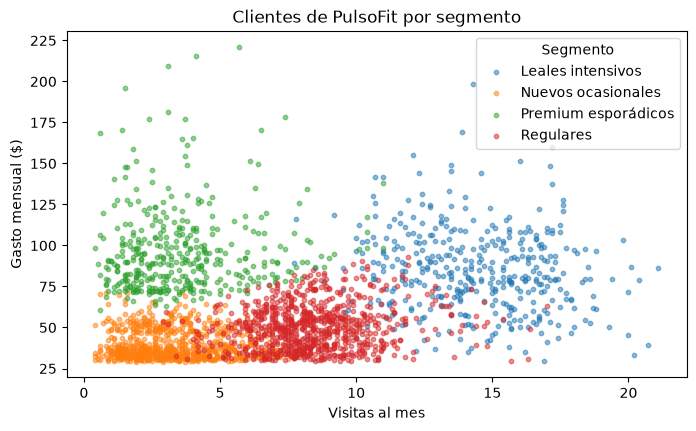

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre, grupo in clientes.groupby("segmento"):
    ax.scatter(grupo["visitas_mes"], grupo["gasto_mensual"], s=10, alpha=0.5, label=nombre)
ax.set_title("Clientes de PulsoFit por segmento")
ax.set_xlabel("Visitas al mes")
ax.set_ylabel("Gasto mensual ($)")
ax.legend(title="Segmento")
plt.show()

- Los **Nuevos ocasionales** son casi un tercio de la cartera (772 clientes): casi todos en plan Básico (76.6 %) y con pocas visitas.
- Los **Regulares** (826 clientes) son el núcleo del negocio: van unas 8 veces al mes y reparten su plan entre Básico y Plus.
- Los **Leales intensivos** (406) llevan años, van más de 3 veces por semana y gastan en extras.
- Los **Premium esporádicos** (396) son el hallazgo más interesante: el 79.5 % paga el plan Premium y gastan más que nadie, pero visitan el gimnasio tan poco como los recién llegados. En el gráfico ocupan la esquina superior izquierda: mucho gasto con pocas visitas.

El plan contratado no basta para describir a los clientes: dos clientes Premium pueden ser un leal intensivo o uno que paga sin usar el servicio. Por eso la segmentación por comportamiento aporta información que el plan no da.

### Tarea 5. Tasa de abandono por segmento

Como `abandono` vale 0 o 1, su media en un grupo es la proporción de clientes que cancelaron en los 3 meses siguientes.

In [7]:
abandono_seg = (
    clientes.groupby("segmento")["abandono"]
    .agg(clientes="size", abandonos="sum", tasa="mean")
    .sort_values("tasa", ascending=False)
)
abandono_seg.round(3)

,clientes,abandonos,tasa
segmento,,,
Nuevos ocasionales,772,354,0.459
Premium esporádicos,396,142,0.359
Regulares,826,154,0.186
Leales intensivos,406,34,0.084


In [8]:
clientes.groupby("plan")["abandono"].agg(clientes="size", abandonos="sum", tasa="mean").round(3)

,clientes,abandonos,tasa
plan,,,
Básico,1080,359,0.332
Plus,743,179,0.241
Premium,577,146,0.253


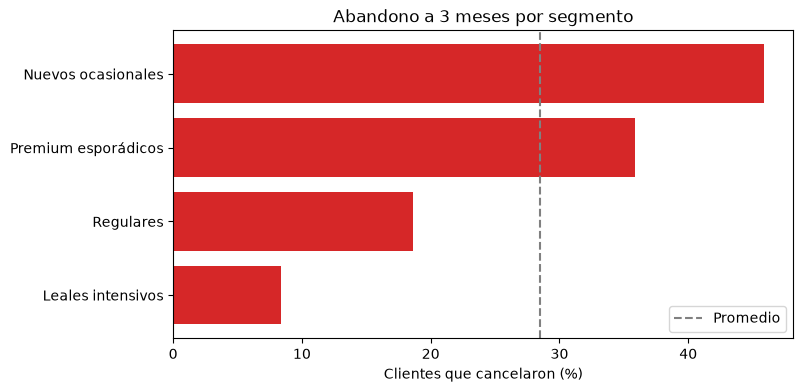

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(abandono_seg.index[::-1], abandono_seg["tasa"][::-1] * 100, color="tab:red")
ax.axvline(clientes["abandono"].mean() * 100, color="gray", linestyle="--", label="Promedio")
ax.set_title("Abandono a 3 meses por segmento")
ax.set_xlabel("Clientes que cancelaron (%)")
ax.legend()
plt.show()

- Los **Nuevos ocasionales** pierden casi la mitad de sus clientes en 3 meses (45.9 %, 354 cancelaciones), seguidos de los **Premium esporádicos** (35.9 %). Los **Leales intensivos** apenas abandonan (8.4 %) y los **Regulares** quedan en medio (18.6 %).
- Por plan, las tasas son más parecidas: Básico 33.2 %, Plus 24.1 % y Premium 25.3 %. La diferencia entre el plan con más y menos abandono es de 9 puntos, mientras que entre segmentos es de casi 38 puntos.
- Por tanto, el **comportamiento** (cuánto viene el cliente y desde cuándo) explica el abandono mucho mejor que el plan. Pagar más no protege contra la cancelación: el cliente Premium que no viene acaba preguntándose para qué paga.

Hay que leerlo como una asociación, no como una causa demostrada: los datos no dicen si el cliente deja de venir porque ya decidió irse o si se va porque dejó de venir. Para la acción comercial basta con saber que una caída de visitas es una señal de alerta.

### Tarea 6. Valor de vida del cliente (CLV)

La fórmula supone que cada mes se va la misma fracción $c$ de clientes. Entonces la probabilidad de seguir activo tras 3 meses es $(1 - c)^3$, y de $1 - p_3 = (1 - c)^3$ se despeja la tasa mensual:

$$c = 1 - (1 - p_3)^{1/3}$$

Con una pérdida mensual constante, la duración de un cliente sigue una distribución geométrica y su **vida esperada es $1/c$ meses**. Multiplicada por el margen mensual del cliente da el CLV:

$$\text{CLV} = \text{gasto mensual medio} \times 0.40 \times \frac{1}{c}$$

Usar directamente $p_3$ como si fuera mensual sería un error: subestimaría la vida esperada aproximadamente a un tercio.

In [10]:
MARGEN = 0.40

clv = clientes.groupby("segmento").agg(
    gasto_medio=("gasto_mensual", "mean"),
    p3=("abandono", "mean"),
)
clv["c_mensual"] = 1 - (1 - clv["p3"]) ** (1 / 3)
clv["vida_meses"] = 1 / clv["c_mensual"]
clv["clv"] = clv["gasto_medio"] * MARGEN * clv["vida_meses"]
clv = clv.sort_values("clv", ascending=False)
clv.round({"gasto_medio": 2, "p3": 3, "c_mensual": 3, "vida_meses": 1, "clv": 0})

,gasto_medio,p3,c_mensual,vida_meses,clv
segmento,,,,,
Leales intensivos,84.46,0.084,0.029,34.8,1176.0
Regulares,50.26,0.186,0.066,15.0,302.0
Premium esporádicos,96.32,0.359,0.138,7.3,280.0
Nuevos ocasionales,39.55,0.459,0.185,5.4,86.0


- Un **Leal intensivo** vale unos **1 176 $** de margen: gasta 84.46 $ al mes y, con una pérdida mensual de solo el 2.9 %, se queda en promedio casi 35 meses. Vale unas 14 veces lo que un **Nuevo ocasional** (86 $), que se queda unos 5 meses y gasta poco.
- Los **Premium esporádicos** gastan más que nadie (96.32 $ al mes), pero su abandono mensual del 13.8 % los deja con una vida de 7.3 meses y un CLV de 280 $, ligeramente por debajo de los **Regulares** (302 $), que gastan casi la mitad.
- Por eso retener vale más donde se combinan gasto alto y abandono alto: si los Premium esporádicos alcanzaran el abandono de los Regulares (6.6 % mensual), su vida esperada pasaría de 7.3 a 15 meses y su CLV se duplicaría con creces.

**Supuestos de la fórmula.** La tasa de abandono es constante cada mes y la misma para todos los clientes del segmento; el gasto y el margen no cambian con el tiempo; no se descuentan los flujos futuros; y se ignora el costo de captación. Es una estimación de orden de magnitud para comparar segmentos, no una valoración contable. Un modelo más fino descontaría los flujos y estimaría la supervivencia por antigüedad.

### Tarea 7. Del análisis al lienzo

El ingreso mensual en riesgo es lo que PulsoFit deja de cobrar cada mes por los clientes que cancelaron: la suma de su `gasto_mensual`.

In [11]:
clientes["gasto_perdido"] = clientes["gasto_mensual"] * clientes["abandono"]

peso = clientes.groupby("segmento").agg(
    clientes=("cliente_id", "size"),
    ingreso_mensual=("gasto_mensual", "sum"),
    ingreso_en_riesgo=("gasto_perdido", "sum"),
)
peso["pct_clientes"] = 100 * peso["clientes"] / peso["clientes"].sum()
peso["pct_ingreso"] = 100 * peso["ingreso_mensual"] / peso["ingreso_mensual"].sum()
peso["pct_riesgo"] = 100 * peso["ingreso_en_riesgo"] / peso["ingreso_en_riesgo"].sum()
peso = peso.join(clv["clv"]).sort_values("ingreso_en_riesgo", ascending=False)
peso[["pct_clientes", "pct_ingreso", "ingreso_en_riesgo", "pct_riesgo", "clv"]].round(1)

,pct_clientes,pct_ingreso,ingreso_en_riesgo,pct_riesgo,clv
segmento,,,,,
Nuevos ocasionales,32.2,21.1,14093.0,36.6,85.5
Premium esporádicos,16.5,26.4,13832.8,35.9,280.0
Regulares,34.4,28.7,7744.0,20.1,302.5
Leales intensivos,16.9,23.7,2812.0,7.3,1175.8


In [12]:
print(f"Ingreso mensual total: {peso['ingreso_mensual'].sum():,.0f} $")
print(f"Ingreso mensual en riesgo: {peso['ingreso_en_riesgo'].sum():,.0f} $ "
      f"({100 * peso['ingreso_en_riesgo'].sum() / peso['ingreso_mensual'].sum():.1f} %)")

Ingreso mensual total: 144,488 $
Ingreso mensual en riesgo: 38,482 $ (26.6 %)


Los dos segmentos con más abandono concentran el **72.5 %** del ingreso mensual en riesgo (36.6 % los Nuevos ocasionales y 35.9 % los Premium esporádicos), aunque solo representan el 48.7 % de los clientes. En total, los clientes que cancelaron pagaban 38 482 $ al mes, el 26.6 % del ingreso mensual.

**Cambios en el lienzo**

- **Segmentos de clientes.** Sustituir la división por plan por los cuatro segmentos de comportamiento. El segmento más valioso en riesgo son los **Premium esporádicos**: generan el 26.4 % del ingreso con solo el 16.5 % de los clientes, y concentran el 35.9 % del ingreso en riesgo.
- **Propuesta de valor.** Para los Premium esporádicos, convertir el pago en uso: una sesión con entrenador para rehacer su plan, reservas prioritarias en clases y recordatorios cuando su asistencia cae. Para los Nuevos ocasionales, un programa de los primeros 90 días con rutina guiada y seguimiento, porque es la etapa en la que más clientes se pierden.
- **Fuentes de ingresos.** Pasar de medir solo altas a medir el **CLV** de cada segmento y decidir cuánto gastar en retener con ese límite: tiene sentido invertir decenas de dólares en retener a un Premium esporádico (280 $ de CLV) y muy poco en promociones de inscripción para clientes que se quedan 5 meses. También se puede ofrecer a los Premium esporádicos un plan intermedio en lugar de perderlos: un cliente que baja a Plus sigue aportando ingreso, uno que cancela no.

**Acción concreta.** Una alerta semanal que marque a los clientes Premium con menos de 4 visitas en el último mes y active una llamada del entrenador. Su efecto debe medirse con un grupo de control antes de extenderla a todas las sedes.

## Conclusiones

- Los datos de acceso que PulsoFit ya registra bastan para segmentar a sus clientes por **comportamiento**; el plan contratado describe mucho peor quién abandona (24 %–33 % por plan frente a 8 %–46 % por segmento).
- El abandono se concentra en los clientes con pocas visitas: Nuevos ocasionales (45.9 % en 3 meses) y Premium esporádicos (35.9 %), que juntos acumulan el 72.5 % del ingreso en riesgo.
- El CLV cambia la prioridad: un Leal intensivo vale unos 1 176 $ y un Nuevo ocasional unos 86 $, así que el negocio gana más reteniendo que captando clientes que se van a los pocos meses.
- En el lienzo, la ciencia de datos actúa sobre **segmentos de clientes**, **relaciones** (alertas de abandono), **propuesta de valor** (acompañamiento personalizado) y **fuentes de ingresos** (inversión en retención según el CLV).
- Las cifras salen de datos observacionales y de una fórmula con supuestos simples: antes de invertir a gran escala conviene validar las acciones de retención con un experimento.